# Capstone — mirrors your deployed research paper

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/yousseftarektalkhan2006-blip/The-ML-internsip/blob/main/work/notebooks/capstone.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

# Preparation with AI

In [16]:
!pip install -q duckdb huggingface_hub

from google.colab import userdata

HF_TOKEN = userdata.get("HF_TOKEN")

print("Token loaded:", HF_TOKEN is not None)

Token loaded: True


In [17]:
import duckdb

con = duckdb.connect()

con.execute(
    f"CREATE OR REPLACE SECRET hf "
    f"(TYPE huggingface, TOKEN '{HF_TOKEN}')"
)

REL = "hf://datasets/FlyRank/internship-warehouse"

In [18]:
con.sql("""
    DESCRIBE
    SELECT *
    FROM read_parquet(
        'hf://datasets/FlyRank/internship-warehouse/dim_content.parquet'
    )
""").df()

,column_name,column_type,null,key,default,extra
0,client_hash_id,VARCHAR,YES,None,None,None
1,content_hash_id,VARCHAR,YES,None,None,None
2,keyword_hash_id,VARCHAR,YES,None,None,None
3,url_hash_id,VARCHAR,YES,None,None,None
4,keyword_char_count,BIGINT,YES,None,None,None
5,keyword_token_count,BIGINT,YES,None,None,None
6,url_char_count,BIGINT,YES,None,None,None
7,content_created_date,DATE,YES,None,None,None
8,content_updated_date,DATE,YES,None,None,None
9,content_type,VARCHAR,YES,None,None,None


In [19]:
con.sql("""
    DESCRIBE
    SELECT *
    FROM read_parquet(
        'hf://datasets/FlyRank/internship-warehouse/fact_content_daily_performance/**/*.parquet'
    )
""").df()

,column_name,column_type,null,key,default,extra
0,report_date,DATE,YES,None,None,None
1,client_hash_id,VARCHAR,YES,None,None,None
2,content_hash_id,VARCHAR,YES,None,None,None
3,client_has_gsc,BOOLEAN,YES,None,None,None
4,client_has_ga4,BOOLEAN,YES,None,None,None
5,gsc_data_available,BOOLEAN,YES,None,None,None
6,ga4_data_available,BOOLEAN,YES,None,None,None
7,gsc_impressions,BIGINT,YES,None,None,None
8,gsc_clicks,BIGINT,YES,None,None,None
9,gsc_sum_position,BIGINT,YES,None,None,None


In [20]:
con.sql("""
    SELECT
        MIN(report_date) AS first_date,
        MAX(report_date) AS last_date,
        COUNT(DISTINCT month) AS number_of_months,
        COUNT(DISTINCT client_hash_id) AS number_of_clients
    FROM read_parquet(
        'hf://datasets/FlyRank/internship-warehouse/fact_content_daily_performance/**/*.parquet'
    )
""").df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,first_date,last_date,number_of_months,number_of_clients
0,2025-01-27,2026-06-30,18,70


In [21]:
con.sql("""
    SELECT
        month,
        COUNT(*) AS rows,
        COUNT(DISTINCT content_hash_id) AS content_pages,
        COUNT(DISTINCT client_hash_id) AS clients,
        SUM(CASE WHEN gsc_data_available THEN 1 ELSE 0 END)
            AS rows_with_gsc,
        SUM(gsc_impressions) AS total_impressions
    FROM read_parquet(
        'hf://datasets/FlyRank/internship-warehouse/fact_content_daily_performance/**/*.parquet'
    )
    WHERE month IN ('2026-01', '2026-02', '2026-03', '2026-04', '2026-05', '2026-06')
    GROUP BY month
    ORDER BY month
""").df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,month,rows,content_pages,clients,rows_with_gsc,total_impressions
0,2026-01,7890817,261984,42,2397143.0,144354689.0
1,2026-02,7355108,321546,54,2621783.0,180128922.0
2,2026-03,9841378,331437,55,3611061.0,280657589.0
3,2026-04,10424730,362172,61,3901060.0,292067218.0
4,2026-05,11687376,389153,66,4373422.0,266164899.0
5,2026-06,11694072,409205,65,3878937.0,216194872.0


In [22]:
con.sql("""
CREATE OR REPLACE TEMP TABLE march_window_audit AS
SELECT
    client_hash_id,
    content_hash_id,

    COUNT(DISTINCT report_date) FILTER (
        WHERE report_date BETWEEN DATE '2026-01-30' AND DATE '2026-02-28'
          AND gsc_data_available = TRUE
    ) AS previous_available_days,

    COUNT(DISTINCT report_date) FILTER (
        WHERE report_date BETWEEN DATE '2026-03-01' AND DATE '2026-03-30'
          AND gsc_data_available = TRUE
    ) AS outcome_available_days,

    SUM(gsc_impressions) FILTER (
        WHERE report_date BETWEEN DATE '2026-01-30' AND DATE '2026-02-28'
          AND gsc_data_available = TRUE
    ) AS previous_impressions,

    SUM(gsc_impressions) FILTER (
        WHERE report_date BETWEEN DATE '2026-03-01' AND DATE '2026-03-30'
          AND gsc_data_available = TRUE
    ) AS outcome_impressions

FROM read_parquet(
    'hf://datasets/FlyRank/internship-warehouse/fact_content_daily_performance/**/*.parquet'
)
WHERE report_date BETWEEN DATE '2026-01-30' AND DATE '2026-03-30'
GROUP BY client_hash_id, content_hash_id
""")

con.sql("""
SELECT
    COUNT(*) AS total_page_pairs,

    COUNT(*) FILTER (
        WHERE previous_available_days > 0
    ) AS pages_with_previous_data,

    COUNT(*) FILTER (
        WHERE outcome_available_days > 0
    ) AS pages_with_outcome_data,

    COUNT(*) FILTER (
        WHERE previous_available_days >= 25
          AND outcome_available_days >= 25
    ) AS pages_with_at_least_25_days_in_both_periods,

    ROUND(AVG(previous_available_days), 2) AS avg_previous_days,
    ROUND(AVG(outcome_available_days), 2) AS avg_outcome_days

FROM march_window_audit
""").df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,total_page_pairs,pages_with_previous_data,pages_with_outcome_data,pages_with_at_least_25_days_in_both_periods,avg_previous_days,avg_outcome_days
0,349205,154609,175205,64858,8.0,9.98


In [23]:
con.sql("""
CREATE OR REPLACE TEMP TABLE march_model_dataset AS
SELECT
    *,
    CASE
        WHEN previous_impressions > 0
         AND outcome_impressions < previous_impressions * 0.80
        THEN 1
        ELSE 0
    END AS is_declining
FROM march_window_audit
WHERE previous_available_days >= 25
  AND outcome_available_days >= 25
  AND previous_impressions > 0
""")

con.sql("""
SELECT
    COUNT(*) AS eligible_pages,
    SUM(is_declining) AS declining_pages,
    COUNT(*) - SUM(is_declining) AS non_declining_pages,
    ROUND(AVG(is_declining) * 100, 2) AS decline_percentage
FROM march_model_dataset
""").df()

,eligible_pages,declining_pages,non_declining_pages,decline_percentage
0,64858,14135.0,50723.0,21.79


In [24]:
con.sql("""
SELECT
    content_type,
    COUNT(*) AS content_count,
    COUNT(content_created_date) AS has_created_date,
    COUNT(content_updated_date) AS has_updated_date,
    COUNT(last_optimized_date) AS has_optimized_date,
    COUNT(word_count) AS has_word_count,
    COUNT(char_count) AS has_char_count
FROM read_parquet(
    'hf://datasets/FlyRank/internship-warehouse/dim_content.parquet'
)
GROUP BY content_type
ORDER BY content_count DESC
""").df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,content_type,content_count,has_created_date,has_updated_date,has_optimized_date,has_word_count,has_char_count
0,keyword article,459174,459174,459174,45360,284339,284339
1,feedly article,57024,57024,57024,13,54094,54094
2,comparison article,3408,3408,3408,23,3405,3405


In [25]:
con.sql("""
CREATE OR REPLACE TEMP TABLE march_features AS

SELECT
    client_hash_id,
    content_hash_id,

    COUNT(DISTINCT report_date) FILTER (
        WHERE gsc_data_available = TRUE
    ) AS gsc_available_days,

    SUM(gsc_impressions) FILTER (
        WHERE gsc_data_available = TRUE
    ) AS previous_impressions,

    SUM(gsc_clicks) FILTER (
        WHERE gsc_data_available = TRUE
    ) AS previous_clicks,

    AVG(gsc_avg_position) FILTER (
        WHERE gsc_data_available = TRUE
          AND gsc_avg_position > 0
    ) AS previous_avg_position,

    COUNT(DISTINCT report_date) FILTER (
        WHERE ga4_data_available = TRUE
    ) AS ga4_available_days,

    SUM(ga4_pageviews) FILTER (
        WHERE ga4_data_available = TRUE
    ) AS previous_pageviews,

    SUM(ga4_sessions) FILTER (
        WHERE ga4_data_available = TRUE
    ) AS previous_sessions,

    SUM(ga4_engaged_sessions) FILTER (
        WHERE ga4_data_available = TRUE
    ) AS previous_engaged_sessions

FROM read_parquet(
    'hf://datasets/FlyRank/internship-warehouse/fact_content_daily_performance/**/*.parquet'
)

WHERE report_date BETWEEN DATE '2026-01-30' AND DATE '2026-02-28'

GROUP BY client_hash_id, content_hash_id
""")

con.sql("""
SELECT
    COUNT(*) AS feature_rows,
    COUNT(previous_impressions) AS rows_with_impressions,
    COUNT(previous_pageviews) AS rows_with_pageviews,
    COUNT(previous_avg_position) AS rows_with_avg_position
FROM march_features
""").df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,feature_rows,rows_with_impressions,rows_with_pageviews,rows_with_avg_position
0,321546,154609,33898,153061


In [26]:
con.sql("""
CREATE OR REPLACE TEMP TABLE march_training_data AS
SELECT
    t.client_hash_id,
    t.content_hash_id,

    -- Target
    t.is_declining,

    -- Historical search features
    f.previous_impressions,
    f.previous_clicks,
    f.previous_avg_position,

    -- Historical analytics features
    f.previous_pageviews,
    f.previous_sessions,
    f.previous_engaged_sessions

FROM march_model_dataset t

INNER JOIN march_features f
    ON t.client_hash_id = f.client_hash_id
   AND t.content_hash_id = f.content_hash_id
""")

con.sql("""
SELECT
    COUNT(*) AS training_rows,
    COUNT(DISTINCT client_hash_id) AS clients,
    SUM(is_declining) AS declining_pages,
    COUNT(previous_pageviews) AS rows_with_pageviews,
    COUNT(previous_avg_position) AS rows_with_avg_position
FROM march_training_data
""").df()

,training_rows,clients,declining_pages,rows_with_pageviews,rows_with_avg_position
0,64858,25,14135.0,17486,64858


In [27]:
con.sql("""
SELECT
    COUNT(*) AS total_rows,

    COUNT(*) FILTER (
        WHERE previous_impressions IS NULL
    ) AS missing_impressions,

    COUNT(*) FILTER (
        WHERE previous_clicks IS NULL
    ) AS missing_clicks,

    COUNT(*) FILTER (
        WHERE previous_avg_position IS NULL
    ) AS missing_avg_position,

    COUNT(*) FILTER (
        WHERE previous_pageviews IS NULL
    ) AS missing_pageviews,

    COUNT(*) FILTER (
        WHERE previous_sessions IS NULL
    ) AS missing_sessions,

    COUNT(*) FILTER (
        WHERE previous_engaged_sessions IS NULL
    ) AS missing_engaged_sessions

FROM march_training_data
""").df()

,total_rows,missing_impressions,missing_clicks,missing_avg_position,missing_pageviews,missing_sessions,missing_engaged_sessions
0,64858,0,0,0,47372,47372,47372


In [28]:
con.sql("""
CREATE OR REPLACE TEMP TABLE march_metadata_audit AS
SELECT
    t.client_hash_id,
    t.content_hash_id,
    d.content_type,
    d.content_created_date,
    d.content_updated_date,
    d.word_count,

    CASE
        WHEN d.content_created_date <= DATE '2026-02-28'
        THEN DATE_DIFF(
            'day',
            d.content_created_date,
            DATE '2026-02-28'
        )
        ELSE NULL
    END AS content_age_days,

    CASE
        WHEN d.content_updated_date <= DATE '2026-02-28'
        THEN DATE_DIFF(
            'day',
            d.content_updated_date,
            DATE '2026-02-28'
        )
        ELSE NULL
    END AS days_since_update

FROM march_training_data t

LEFT JOIN read_parquet(
    'hf://datasets/FlyRank/internship-warehouse/dim_content.parquet'
) d
    ON t.client_hash_id = d.client_hash_id
   AND t.content_hash_id = d.content_hash_id
""")

con.sql("""
SELECT
    COUNT(*) AS total_rows,
    COUNT(content_type) AS rows_with_content_type,
    COUNT(content_age_days) AS rows_with_content_age,
    COUNT(days_since_update) AS rows_with_update_age,
    COUNT(word_count) AS rows_with_word_count,
    COUNT(*) FILTER (
        WHERE content_updated_date > DATE '2026-02-28'
    ) AS updates_after_cutoff
FROM march_metadata_audit
""").df()

,total_rows,rows_with_content_type,rows_with_content_age,rows_with_update_age,rows_with_word_count,updates_after_cutoff
0,64858,64858,64858,15044,40265,49814


In [29]:
con.sql("""
CREATE OR REPLACE TEMP TABLE march_model_inputs AS
SELECT
    t.client_hash_id,
    t.content_hash_id,

    -- Target
    t.is_declining,

    -- Historical Google Search Console features
    t.previous_impressions,
    t.previous_clicks,
    t.previous_avg_position,

    -- Content metadata known at the cutoff
    m.content_type,
    m.content_age_days

FROM march_training_data t

INNER JOIN march_metadata_audit m
    ON t.client_hash_id = m.client_hash_id
   AND t.content_hash_id = m.content_hash_id
""")

con.sql("""
SELECT
    COUNT(*) AS total_records,
    COUNT(*) FILTER (WHERE is_declining = 1) AS declining,
    COUNT(*) FILTER (WHERE is_declining = 0) AS non_declining,
    COUNT(*) FILTER (WHERE content_type IS NULL) AS missing_content_type,
    COUNT(*) FILTER (WHERE content_age_days IS NULL) AS missing_content_age
FROM march_model_inputs
""").df()

,total_records,declining,non_declining,missing_content_type,missing_content_age
0,64858,14135,50723,0,0


In [30]:
con.sql("""
CREATE OR REPLACE TEMP TABLE march_model_dataset_v2 AS

WITH eligible AS (
    SELECT
        *,
        previous_impressions * 1.0
            / previous_available_days AS previous_daily_impressions,

        outcome_impressions * 1.0
            / outcome_available_days AS outcome_daily_impressions

    FROM march_window_audit

    WHERE previous_available_days >= 25
      AND outcome_available_days >= 25
      AND previous_impressions > 0
)

SELECT
    *,
    CASE
        WHEN outcome_daily_impressions
             < previous_daily_impressions * 0.80
        THEN 1
        ELSE 0
    END AS is_declining

FROM eligible
""")

con.sql("""
CREATE OR REPLACE TEMP TABLE march_model_inputs_v2 AS

SELECT
    t.client_hash_id,
    t.content_hash_id,
    t.is_declining,

    -- Historical daily averages
    f.previous_impressions * 1.0
        / f.gsc_available_days AS previous_daily_impressions,

    f.previous_clicks * 1.0
        / f.gsc_available_days AS previous_daily_clicks,

    f.previous_avg_position,

    -- Content metadata
    m.content_type,
    m.content_age_days

FROM march_model_dataset_v2 t

INNER JOIN march_features f
    ON t.client_hash_id = f.client_hash_id
   AND t.content_hash_id = f.content_hash_id

INNER JOIN march_metadata_audit m
    ON t.client_hash_id = m.client_hash_id
   AND t.content_hash_id = m.content_hash_id
""")

con.sql("""
SELECT
    COUNT(*) AS total_records,
    SUM(is_declining) AS declining_records,
    COUNT(*) - SUM(is_declining) AS non_declining_records,
    ROUND(AVG(is_declining) * 100, 2) AS decline_percentage
FROM march_model_inputs_v2
""").df()

,total_records,declining_records,non_declining_records,decline_percentage
0,64858,13709.0,51149.0,21.14


In [31]:
con.sql("""
SELECT
    client_hash_id,
    COUNT(*) AS page_pairs,
    SUM(is_declining) AS declining_pairs,
    ROUND(AVG(is_declining) * 100, 2) AS decline_percentage
FROM march_model_inputs_v2
GROUP BY client_hash_id
ORDER BY page_pairs DESC
""").df()

,client_hash_id,page_pairs,declining_pairs,decline_percentage
0,client_73cda7b4e4f265ea,18207,4190.0,23.01
1,client_62f4a7e64f5e0096,14634,3698.0,25.27
2,client_23a62021009f63c4,8924,1833.0,20.54
3,client_e547b89c05043229,8299,1311.0,15.80
4,client_fef1a8f436438636,6283,710.0,11.30
5,client_08a6a72ff48e62c0,3949,1180.0,29.88
6,client_9958f0a7ae1df715,1523,303.0,19.89
7,client_3197e6291363b4db,729,156.0,21.40
8,client_ff644d8251367cbb,709,47.0,6.63
9,client_400c21c81c8b46ef,617,47.0,7.62


In [32]:
import pandas as pd
from sklearn.model_selection import GroupKFold

# Load the corrected modeling dataset from DuckDB
df = con.execute(
    "SELECT * FROM march_model_inputs_v2"
).df()

# Create five folds, keeping each client's records together
group_kfold = GroupKFold(n_splits=5)

for fold, (train_idx, test_idx) in enumerate(
    group_kfold.split(
        df,
        df["is_declining"],
        groups=df["client_hash_id"]
    ),
    start=1
):
    train_data = df.iloc[train_idx]
    test_data = df.iloc[test_idx]

    train_clients = set(train_data["client_hash_id"])
    test_clients = set(test_data["client_hash_id"])

    print(f"FOLD {fold}")
    print("Training records:", len(train_data))
    print("Testing records:", len(test_data))
    print("Training clients:", len(train_clients))
    print("Testing clients:", len(test_clients))
    print(
        "Training decline rate:",
        round(train_data["is_declining"].mean() * 100, 2), "%"
    )
    print(
        "Testing decline rate:",
        round(test_data["is_declining"].mean() * 100, 2), "%"
    )
    print("Client overlap:", len(train_clients & test_clients))
    print("-" * 40)

FOLD 1
Training records: 46651
Testing records: 18207
Training clients: 24
Testing clients: 1
Training decline rate: 20.4 %
Testing decline rate: 23.01 %
Client overlap: 0
----------------------------------------
FOLD 2
Training records: 50224
Testing records: 14634
Training clients: 24
Testing clients: 1
Training decline rate: 19.93 %
Testing decline rate: 25.27 %
Client overlap: 0
----------------------------------------
FOLD 3
Training records: 54185
Testing records: 10673
Training clients: 17
Testing clients: 8
Training decline rate: 21.39 %
Testing decline rate: 19.87 %
Client overlap: 0
----------------------------------------
FOLD 4
Training records: 54186
Testing records: 10672
Training clients: 17
Testing clients: 8
Training decline rate: 22.14 %
Testing decline rate: 16.06 %
Client overlap: 0
----------------------------------------
FOLD 5
Training records: 54186
Testing records: 10672
Training clients: 18
Testing clients: 7
Training decline rate: 21.63 %
Testing decline rate

In [33]:
# Load our corrected SQL dataset into a pandas DataFrame
df = con.execute("""
    SELECT *
    FROM march_model_inputs_v2
""").df()

print("Dataset shape:", df.shape)
print("Decline rate:", round(df["is_declining"].mean() * 100, 2), "%")

df.head()

Dataset shape: (64858, 8)
Decline rate: 21.14 %


,client_hash_id,content_hash_id,is_declining,previous_daily_impressions,previous_daily_clicks,previous_avg_position,content_type,content_age_days
0,client_e547b89c05043229,content_7292af5ee9096ce1,0,20.233333,0.000000,28.713545,keyword article,199
1,client_e547b89c05043229,content_14a6ade39e9a8e31,0,19.366667,0.033333,15.105880,keyword article,199
2,client_e547b89c05043229,content_2618be372e19730f,0,9.900000,0.000000,22.720854,keyword article,199
3,client_e547b89c05043229,content_1da7d268111c5875,0,27.100000,0.000000,12.305406,keyword article,199
4,client_e547b89c05043229,content_9f2548ccefcf3cea,0,7.758621,0.000000,9.261786,keyword article,199


In [34]:
import pandas as pd
import numpy as np

from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# Features available before the prediction cutoff
numeric_features = [
    "previous_daily_impressions",
    "previous_daily_clicks",
    "previous_avg_position",
    "content_age_days"
]

categorical_features = [
    "content_type"
]

feature_columns = numeric_features + categorical_features

X = df[feature_columns]
y = df["is_declining"]
groups = df["client_hash_id"]

# Keep every client's records together
cv = GroupKFold(n_splits=5)

# Prepare numeric and categorical features
preprocessor = ColumnTransformer([
    ("numeric", SimpleImputer(strategy="median"), numeric_features),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features)
])

# Random Forest model
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=10,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Simple majority-class baseline
baseline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DummyClassifier(strategy="most_frequent"))
])

results = []

for fold, (train_idx, test_idx) in enumerate(
    cv.split(X, y, groups), start=1
):

    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    # Train both approaches
    model.fit(X_train, y_train)
    baseline.fit(X_train, y_train)

    # Model predictions
    model_predictions = model.predict(X_test)
    model_probabilities = model.predict_proba(X_test)[:, 1]

    # Baseline predictions
    baseline_predictions = baseline.predict(X_test)

    results.append({
        "fold": fold,
        "test_clients": groups.iloc[test_idx].nunique(),

        "model_accuracy": accuracy_score(y_test, model_predictions),
        "model_precision": precision_score(
            y_test, model_predictions, zero_division=0
        ),
        "model_recall": recall_score(
            y_test, model_predictions, zero_division=0
        ),
        "model_f1": f1_score(
            y_test, model_predictions, zero_division=0
        ),
        "model_roc_auc": roc_auc_score(y_test, model_probabilities),
        "model_pr_auc": average_precision_score(
            y_test, model_probabilities
        ),

        "baseline_accuracy": accuracy_score(
            y_test, baseline_predictions
        ),
        "baseline_f1": f1_score(
            y_test, baseline_predictions, zero_division=0
        )
    })

results_df = pd.DataFrame(results)

display(results_df.round(3))

print("\nAVERAGE PERFORMANCE ACROSS FIVE FOLDS")
display(results_df.drop(columns=["fold", "test_clients"]).mean().round(3))

,fold,test_clients,model_accuracy,model_precision,model_recall,model_f1,model_roc_auc,model_pr_auc,baseline_accuracy,baseline_f1
0,1,1,0.666,0.276,0.276,0.276,0.574,0.272,0.770,0.0
1,2,1,0.590,0.289,0.428,0.345,0.557,0.303,0.747,0.0
2,3,8,0.743,0.316,0.252,0.281,0.654,0.301,0.801,0.0
3,4,8,0.664,0.175,0.295,0.220,0.537,0.174,0.839,0.0
4,5,7,0.654,0.222,0.342,0.269,0.548,0.210,0.814,0.0



AVERAGE PERFORMANCE ACROSS FIVE FOLDS


,0
model_accuracy,0.663
model_precision,0.256
model_recall,0.319
model_f1,0.278
model_roc_auc,0.574
model_pr_auc,0.252
baseline_accuracy,0.794
baseline_f1,0.000


In [35]:
from sklearn.base import clone
from sklearn.metrics import (
    precision_score,
    recall_score,
    roc_auc_score,
    average_precision_score
)

oof_results = []

for fold, (train_idx, test_idx) in enumerate(
    cv.split(X, y, groups), start=1
):
    fold_model = clone(model)

    fold_model.fit(X.iloc[train_idx], y.iloc[train_idx])

    probabilities = fold_model.predict_proba(
        X.iloc[test_idx]
    )[:, 1]

    fold_output = pd.DataFrame({
        "fold": fold,
        "actual": y.iloc[test_idx].values,
        "predicted_probability": probabilities
    })

    oof_results.append(fold_output)

oof = pd.concat(oof_results, ignore_index=True)

# Evaluate the highest-ranked 10% and 20% within each fold
ranking_results = []

for fold in sorted(oof["fold"].unique()):
    fold_data = oof[oof["fold"] == fold].copy()

    fold_data = fold_data.sort_values(
        "predicted_probability",
        ascending=False
    )

    total_decline_rate = fold_data["actual"].mean()

    for percentage in [0.10, 0.20]:
        top_count = max(1, int(len(fold_data) * percentage))
        top_pages = fold_data.head(top_count)

        precision = top_pages["actual"].mean()
        recall = (
            top_pages["actual"].sum()
            / fold_data["actual"].sum()
            if fold_data["actual"].sum() > 0 else 0
        )

        ranking_results.append({
            "fold": fold,
            "top_percentage": percentage * 100,
            "pages_selected": top_count,
            "precision_at_top": precision,
            "recall_at_top": recall,
            "overall_decline_rate": total_decline_rate,
            "lift": (
                precision / total_decline_rate
                if total_decline_rate > 0 else 0
            )
        })

ranking_df = pd.DataFrame(ranking_results)

display(ranking_df.round(3))

print("POOLED OUT-OF-FOLD PERFORMANCE")

print(
    "ROC-AUC:",
    round(roc_auc_score(oof["actual"], oof["predicted_probability"]), 3)
)

print(
    "PR-AUC:",
    round(average_precision_score(
        oof["actual"], oof["predicted_probability"]
    ), 3)
)

,fold,top_percentage,pages_selected,precision_at_top,recall_at_top,overall_decline_rate,lift
0,1,10.0,1820,0.302,0.131,0.230,1.311
1,1,20.0,3641,0.281,0.244,0.230,1.220
2,2,10.0,1463,0.364,0.144,0.253,1.442
3,2,20.0,2926,0.319,0.252,0.253,1.260
4,3,10.0,1067,0.342,0.172,0.199,1.721
5,3,20.0,2134,0.307,0.309,0.199,1.547
6,4,10.0,1067,0.187,0.116,0.161,1.161
7,4,20.0,2134,0.172,0.214,0.161,1.071
8,5,10.0,1067,0.221,0.119,0.186,1.189
9,5,20.0,2134,0.225,0.242,0.186,1.211


POOLED OUT-OF-FOLD PERFORMANCE
ROC-AUC: 0.575
PR-AUC: 0.256


In [36]:
heuristic_results = []

for fold, (_, test_idx) in enumerate(
    cv.split(X, y, groups), start=1
):
    fold_data = df.iloc[test_idx].copy()

    for method, column, ascending in [
        ("Visibility first", "previous_daily_impressions", False),
        ("Worst position first", "previous_avg_position", False)
    ]:

        ranked = fold_data.sort_values(
            column,
            ascending=ascending
        )

        total_declines = ranked["is_declining"].sum()
        overall_rate = ranked["is_declining"].mean()

        for percentage in [0.10, 0.20]:
            top_count = max(1, int(len(ranked) * percentage))
            selected = ranked.head(top_count)

            precision = selected["is_declining"].mean()
            recall = (
                selected["is_declining"].sum() / total_declines
                if total_declines > 0 else 0
            )

            heuristic_results.append({
                "fold": fold,
                "method": method,
                "top_percentage": percentage * 100,
                "precision": precision,
                "recall": recall,
                "lift": precision / overall_rate
            })

heuristic_df = pd.DataFrame(heuristic_results)

display(
    heuristic_df.round(3).sort_values(
        ["method", "top_percentage", "fold"]
    )
)

print("\nAVERAGE HEURISTIC PERFORMANCE")
display(
    heuristic_df.groupby(
        ["method", "top_percentage"]
    )[["precision", "recall", "lift"]].mean().round(3)
)

,fold,method,top_percentage,precision,recall,lift
0,1,Visibility first,10.0,0.276,0.120,1.201
4,2,Visibility first,10.0,0.256,0.101,1.012
8,3,Visibility first,10.0,0.133,0.067,0.670
12,4,Visibility first,10.0,0.246,0.153,1.535
16,5,Visibility first,10.0,0.191,0.103,1.027
1,1,Visibility first,20.0,0.269,0.233,1.167
5,2,Visibility first,20.0,0.257,0.203,1.017
9,3,Visibility first,20.0,0.145,0.146,0.729
13,4,Visibility first,20.0,0.241,0.300,1.503
17,5,Visibility first,20.0,0.133,0.142,0.713



AVERAGE HEURISTIC PERFORMANCE


precision  recall   lift
method               top_percentage                          
Visibility first     10.0                0.221   0.109  1.089
                     20.0                0.209   0.205  1.026
Worst position first 10.0                0.130   0.063  0.630
                     20.0                0.152   0.144  0.718

In [37]:
# Combine the out-of-fold predictions and both heuristic scores
comparison_data = df.iloc[
    np.concatenate([
        test_idx for _, test_idx in cv.split(X, y, groups)
    ])
].copy()

# Add fold identifiers and Random Forest probabilities
comparison_data["fold"] = oof["fold"].values
comparison_data["rf_score"] = oof["predicted_probability"].values

ranking_methods = {
    "Random Forest": "rf_score",
    "Visibility first": "previous_daily_impressions",
    "Worst position first": "previous_avg_position"
}

pooled_results = []

for method, score_column in ranking_methods.items():

    for percentage in [0.10, 0.20]:

        selected_records = []
        total_records = 0
        total_declines = 0

        for fold in sorted(comparison_data["fold"].unique()):

            fold_data = comparison_data[
                comparison_data["fold"] == fold
            ].sort_values(score_column, ascending=False)

            top_count = max(1, int(len(fold_data) * percentage))
            selected = fold_data.head(top_count)

            selected_records.append(selected)

            total_records += len(fold_data)
            total_declines += fold_data["is_declining"].sum()

        selected_all = pd.concat(selected_records)

        selected_count = len(selected_all)
        selected_declines = selected_all["is_declining"].sum()

        precision = selected_declines / selected_count
        recall = selected_declines / total_declines
        overall_rate = total_declines / total_records

        pooled_results.append({
            "method": method,
            "top_percentage": percentage * 100,
            "selected_records": selected_count,
            "declining_records_found": int(selected_declines),
            "precision": precision,
            "recall": recall,
            "overall_decline_rate": overall_rate,
            "lift": precision / overall_rate
        })

pooled_df = pd.DataFrame(pooled_results)

display(pooled_df.round(3))

,method,top_percentage,selected_records,declining_records_found,precision,recall,overall_decline_rate,lift
0,Random Forest,10.0,6484,1882,0.290,0.137,0.211,1.373
1,Random Forest,20.0,12969,3458,0.267,0.252,0.211,1.261
2,Visibility first,10.0,6484,1486,0.229,0.108,0.211,1.084
3,Visibility first,20.0,12969,2837,0.219,0.207,0.211,1.035
4,Worst position first,10.0,6484,842,0.130,0.061,0.211,0.614
5,Worst position first,20.0,12969,2057,0.159,0.150,0.211,0.750


In [38]:
from sklearn.inspection import permutation_importance
from sklearn.base import clone

importance_results = []

for fold, (train_idx, test_idx) in enumerate(
    cv.split(X, y, groups), start=1
):
    fold_model = clone(model)

    # Avoid nested parallel processing
    fold_model.set_params(classifier__n_jobs=1)

    fold_model.fit(X.iloc[train_idx], y.iloc[train_idx])

    importance = permutation_importance(
        fold_model,
        X.iloc[test_idx],
        y.iloc[test_idx],
        scoring="average_precision",
        n_repeats=3,
        random_state=42,
        n_jobs=-1
    )

    for feature, mean_importance, std_importance in zip(
        feature_columns,
        importance.importances_mean,
        importance.importances_std
    ):
        importance_results.append({
            "fold": fold,
            "feature": feature,
            "importance_mean": mean_importance,
            "importance_std": std_importance
        })

importance_df = pd.DataFrame(importance_results)

summary_importance = (
    importance_df
    .groupby("feature")
    .agg(
        average_importance=("importance_mean", "mean"),
        variation=("importance_mean", "std")
    )
    .sort_values("average_importance", ascending=False)
)

display(summary_importance.round(4))

,average_importance,variation
feature,,
previous_daily_impressions,0.0294,0.0104
previous_avg_position,0.0255,0.0333
previous_daily_clicks,0.0178,0.0186
content_type,0.0032,0.0035
content_age_days,-0.0103,0.0142


In [39]:
from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score, roc_auc_score

# Reduced model: keep only the three useful historical features
reduced_features = [
    "previous_daily_impressions",
    "previous_daily_clicks",
    "previous_avg_position"
]

X_reduced = df[reduced_features]

reduced_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=10,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

full_predictions = []
reduced_predictions = []
actual_values = []
fold_numbers = []

for fold, (train_idx, test_idx) in enumerate(
    cv.split(X, y, groups), start=1
):

    # Original five-feature model
    full_fold_model = clone(model)
    full_fold_model.fit(X.iloc[train_idx], y.iloc[train_idx])

    full_prob = full_fold_model.predict_proba(
        X.iloc[test_idx]
    )[:, 1]

    # Reduced three-feature model
    reduced_fold_model = clone(reduced_model)
    reduced_fold_model.fit(
        X_reduced.iloc[train_idx],
        y.iloc[train_idx]
    )

    reduced_prob = reduced_fold_model.predict_proba(
        X_reduced.iloc[test_idx]
    )[:, 1]

    full_predictions.extend(full_prob)
    reduced_predictions.extend(reduced_prob)
    actual_values.extend(y.iloc[test_idx])
    fold_numbers.extend([fold] * len(test_idx))

comparison = pd.DataFrame({
    "fold": fold_numbers,
    "actual": actual_values,
    "full_probability": full_predictions,
    "reduced_probability": reduced_predictions
})

# Compare overall classification ranking metrics
print("FULL MODEL")
print("PR-AUC:", round(average_precision_score(
    comparison["actual"], comparison["full_probability"]
), 3))
print("ROC-AUC:", round(roc_auc_score(
    comparison["actual"], comparison["full_probability"]
), 3))

print("\nREDUCED MODEL")
print("PR-AUC:", round(average_precision_score(
    comparison["actual"], comparison["reduced_probability"]
), 3))
print("ROC-AUC:", round(roc_auc_score(
    comparison["actual"], comparison["reduced_probability"]
), 3))

# Compare pooled top-10% ranking performance
for model_name, score_column in [
    ("Full model", "full_probability"),
    ("Reduced model", "reduced_probability")
]:
    selected_parts = []

    for fold in sorted(comparison["fold"].unique()):
        fold_data = comparison[
            comparison["fold"] == fold
        ].sort_values(score_column, ascending=False)

        top_count = max(1, int(len(fold_data) * 0.10))
        selected_parts.append(fold_data.head(top_count))

    selected = pd.concat(selected_parts)

    precision = selected["actual"].mean()
    overall_rate = comparison["actual"].mean()

    print(
        f"{model_name} top-10% precision: {precision:.3f} | "
        f"Lift: {precision / overall_rate:.3f}"
    )

FULL MODEL
PR-AUC: 0.256
ROC-AUC: 0.575

REDUCED MODEL
PR-AUC: 0.275
ROC-AUC: 0.597
Full model top-10% precision: 0.290 | Lift: 1.373
Reduced model top-10% precision: 0.317 | Lift: 1.498


In [40]:
reduced_fold_results = []

for fold in sorted(comparison["fold"].unique()):

    fold_data = comparison[
        comparison["fold"] == fold
    ].copy()

    actual = fold_data["actual"]
    probabilities = fold_data["reduced_probability"]

    fold_data = fold_data.sort_values(
        "reduced_probability",
        ascending=False
    )

    overall_rate = actual.mean()

    result = {
        "fold": fold,
        "records": len(fold_data),
        "decline_rate": overall_rate,
        "pr_auc": average_precision_score(
            actual, probabilities
        ),
        "roc_auc": roc_auc_score(
            actual, probabilities
        )
    }

    for percentage in [0.10, 0.20]:

        top_count = max(
            1, int(len(fold_data) * percentage)
        )

        selected = fold_data.head(top_count)
        precision = selected["actual"].mean()

        result[f"top_{int(percentage*100)}_precision"] = precision
        result[f"top_{int(percentage*100)}_lift"] = (
            precision / overall_rate
        )

    reduced_fold_results.append(result)

reduced_fold_df = pd.DataFrame(reduced_fold_results)

display(reduced_fold_df.round(3))

print("\nAVERAGE ACROSS FOLDS")
display(
    reduced_fold_df.drop(
        columns=["fold", "records"]
    ).mean().round(3)
)

,fold,records,decline_rate,pr_auc,roc_auc,top_10_precision,top_10_lift,top_20_precision,top_20_lift
0,1,18207,0.230,0.294,0.589,0.348,1.511,0.313,1.359
1,2,14634,0.253,0.305,0.576,0.346,1.369,0.310,1.225
2,3,10673,0.199,0.296,0.640,0.345,1.736,0.311,1.566
3,4,10672,0.161,0.205,0.591,0.238,1.482,0.208,1.295
4,5,10672,0.186,0.229,0.563,0.274,1.471,0.239,1.284



AVERAGE ACROSS FOLDS


,0
decline_rate,0.206
pr_auc,0.266
roc_auc,0.592
top_10_precision,0.310
top_10_lift,1.514
top_20_precision,0.276
top_20_lift,1.346


In [41]:
# Inspect the out-of-fold predictions
print("COMPARISON DATAFRAME")
print("Shape:", comparison.shape)
print("Columns:", comparison.columns.tolist())
print("\nFirst five rows:")
display(comparison.head())

print("\nIndex information:")
print("Index type:", type(comparison.index))
print("Index name:", comparison.index.name)
print("First five index values:", comparison.index[:5].tolist())


# Find other DataFrames available in the notebook
print("\nOTHER DATAFRAMES")
dataframes = [
    (name, obj.shape)
    for name, obj in list(globals().items())
    if isinstance(obj, pd.DataFrame)
]

for name, shape in dataframes:
    print(name, shape)

COMPARISON DATAFRAME
Shape: (64858, 4)
Columns: ['fold', 'actual', 'full_probability', 'reduced_probability']

First five rows:


,fold,actual,full_probability,reduced_probability
0,1,0,0.444853,0.258986
1,1,0,0.090083,0.054390
2,1,0,0.460303,0.346186
3,1,0,0.399456,0.514669
4,1,0,0.212934,0.244135



Index information:
Index type: <class 'pandas.core.indexes.range.RangeIndex'>
Index name: None
First five index values: [0, 1, 2, 3, 4]

OTHER DATAFRAMES
__ (25, 4)
___ (1, 4)
_8 (26, 6)
_9 (31, 6)
_10 (1, 4)
_11 (6, 6)
_12 (1, 6)
_13 (1, 4)
_14 (3, 7)
_15 (1, 4)
_18 (26, 6)
_19 (31, 6)
_20 (1, 4)
_21 (6, 6)
_22 (1, 6)
_23 (1, 4)
_24 (3, 7)
_25 (1, 4)
_26 (1, 5)
_27 (1, 7)
_28 (1, 6)
_29 (1, 5)
_30 (1, 4)
_31 (25, 4)
df (64858, 8)
train_data (54186, 8)
test_data (10672, 8)
_33 (5, 8)
X (64858, 5)
X_train (54186, 5)
X_test (10672, 5)
results_df (5, 10)
fold_output (10672, 3)
oof (64858, 3)
fold_data (10672, 4)
top_pages (2134, 3)
ranking_df (10, 7)
ranked (10672, 8)
selected (2134, 4)
heuristic_df (20, 6)
comparison_data (64858, 10)
selected_all (12969, 10)
pooled_df (6, 8)
importance_df (25, 4)
summary_importance (5, 2)
X_reduced (64858, 3)
comparison (64858, 4)
reduced_fold_df (5, 9)


In [42]:
# Inspect comparison_data
print("COMPARISON_DATA")
print("Shape:", comparison_data.shape)
print("Columns:", comparison_data.columns.tolist())
display(comparison_data.head())

# Check whether its predictions match comparison
print("\nPREDICTION ALIGNMENT CHECK")

print(
    "Actual labels match:",
    comparison_data["actual"].reset_index(drop=True).equals(
        comparison["actual"].reset_index(drop=True)
    )
)

print(
    "Reduced probabilities match:",
    np.allclose(
        comparison_data["reduced_probability"].to_numpy(),
        comparison["reduced_probability"].to_numpy()
    )
)

COMPARISON_DATA
Shape: (64858, 10)
Columns: ['client_hash_id', 'content_hash_id', 'is_declining', 'previous_daily_impressions', 'previous_daily_clicks', 'previous_avg_position', 'content_type', 'content_age_days', 'fold', 'rf_score']


,client_hash_id,content_hash_id,is_declining,previous_daily_impressions,previous_daily_clicks,previous_avg_position,content_type,content_age_days,fold,rf_score
9654,client_73cda7b4e4f265ea,content_d4d6ce694cda27e5,0,29.000000,0.033333,8.445633,keyword article,212,1,0.444853
9655,client_73cda7b4e4f265ea,content_e70f13b9a468bc43,0,3.153846,0.000000,28.230615,keyword article,212,1,0.090083
9656,client_73cda7b4e4f265ea,content_7b5b6de2e1e4851a,0,15.366667,0.033333,13.887193,keyword article,212,1,0.460303
9657,client_73cda7b4e4f265ea,content_653a20c576af83ca,0,6.433333,0.033333,26.699620,keyword article,212,1,0.399456
9658,client_73cda7b4e4f265ea,content_d8efdec609860ce6,0,4.230769,0.000000,10.344231,keyword article,212,1,0.212934



PREDICTION ALIGNMENT CHECK


KeyError: 'actual'

In [43]:
# Compare the labels and predictions in both DataFrames

labels_match = np.array_equal(
    comparison_data["is_declining"].to_numpy(),
    comparison["actual"].to_numpy()
)

scores_match = np.allclose(
    comparison_data["rf_score"].to_numpy(),
    comparison["reduced_probability"].to_numpy()
)

print("Actual labels match:", labels_match)
print("Reduced probabilities match:", scores_match)

print("\nNumber of records:")
print("comparison:", len(comparison))
print("comparison_data:", len(comparison_data))

Actual labels match: True
Reduced probabilities match: False

Number of records:
comparison: 64858
comparison_data: 64858


In [44]:
print(
    "RF scores match full model:",
    np.allclose(
        comparison_data["rf_score"].to_numpy(),
        comparison["full_probability"].to_numpy()
    )
)

print(
    "Labels match:",
    np.array_equal(
        comparison_data["is_declining"].to_numpy(),
        comparison["actual"].to_numpy()
    )
)

RF scores match full model: True
Labels match: True


In [45]:
# Create a separate copy of the prediction data
ranked_recommendations = comparison_data.copy()

# Use the reduced Random Forest probabilities
ranked_recommendations["priority_score"] = (
    comparison["reduced_probability"].to_numpy()
)

# Sort from highest predicted decline probability to lowest
ranked_recommendations = ranked_recommendations.sort_values(
    "priority_score",
    ascending=False
).reset_index(drop=True)

# Assign a unique ranking position
ranked_recommendations.insert(
    0,
    "priority_rank",
    range(1, len(ranked_recommendations) + 1)
)

# Display the top 20 recommendations
display(
    ranked_recommendations[
        [
            "priority_rank",
            "client_hash_id",
            "content_hash_id",
            "priority_score",
            "previous_daily_impressions",
            "previous_daily_clicks",
            "previous_avg_position"
        ]
    ].head(20)
)

# Check the ranking output
print("\nTotal ranked records:", len(ranked_recommendations))
print(
    "Highest priority score:",
    ranked_recommendations["priority_score"].max()
)
print(
    "Lowest priority score:",
    ranked_recommendations["priority_score"].min()
)

,priority_rank,client_hash_id,content_hash_id,priority_score,previous_daily_impressions,previous_daily_clicks,previous_avg_position
0,1,client_e547b89c05043229,content_17e2e3ad59b9af37,0.889402,304.966667,0.000000,8.073594
1,2,client_73cda7b4e4f265ea,content_bba2014e7be2e937,0.888335,233.033333,0.000000,6.910240
2,3,client_fef1a8f436438636,content_5cc6fa5852bf25f1,0.888028,219.133333,0.000000,1.322420
3,4,client_23a62021009f63c4,content_66d3e7a515e4ec68,0.881530,426.100000,0.000000,2.389796
4,5,client_ff644d8251367cbb,content_c7ef90df57c40cf3,0.879418,112.400000,0.000000,3.932379
5,6,client_23a62021009f63c4,content_a8781e2d0ba34358,0.878706,216.033333,0.000000,3.100484
6,7,client_62f4a7e64f5e0096,content_8184ed1c5257cc60,0.874843,45.866667,0.000000,2.436692
7,8,client_62f4a7e64f5e0096,content_32c983eb3434e525,0.872258,46.533333,0.000000,2.376228
8,9,client_62f4a7e64f5e0096,content_fd5b9711d906956b,0.869685,119.766667,0.000000,2.496535
9,10,client_65de48885f4ef01b,content_df6a9b44e683db63,0.868755,220.566667,0.000000,5.899496



Total ranked records: 64858
Highest priority score: 0.8894024538503124
Lowest priority score: 0.0036683099312264946


In [46]:
# Add priority categories based on ranking position

total_records = len(ranked_recommendations)

high_limit = int(total_records * 0.10)
medium_limit = int(total_records * 0.20)

ranked_recommendations["priority_category"] = np.where(
    ranked_recommendations["priority_rank"] <= high_limit,
    "High",
    np.where(
        ranked_recommendations["priority_rank"] <= medium_limit,
        "Medium",
        "Monitor"
    )
)

# Add suggested actions
action_map = {
    "High": "Review first",
    "Medium": "Review when capacity allows",
    "Monitor": "Continue monitoring"
}

ranked_recommendations["suggested_action"] = (
    ranked_recommendations["priority_category"].map(action_map)
)

# Identify records with impressions but no recorded clicks
ranked_recommendations["zero_click_flag"] = (
    (ranked_recommendations["previous_daily_impressions"] > 0) &
    (ranked_recommendations["previous_daily_clicks"] == 0)
)

# Add human-readable review reasons
ranked_recommendations["review_reason"] = np.where(
    ranked_recommendations["zero_click_flag"],
    "High predicted decline risk; impressions recorded but no clicks",
    "High predicted decline risk; review historical search performance"
)

# Display the first 20 recommendations
display(
    ranked_recommendations[
        [
            "priority_rank",
            "priority_category",
            "priority_score",
            "suggested_action",
            "review_reason",
            "zero_click_flag"
        ]
    ].head(20)
)

# Summarize the categories
print("\nPRIORITY CATEGORY SUMMARY")

display(
    ranked_recommendations.groupby("priority_category").agg(
        records=("priority_rank", "count"),
        average_score=("priority_score", "mean"),
        average_decline_rate=("is_declining", "mean"),
        zero_click_records=("zero_click_flag", "sum")
    ).round(3)
)

,priority_rank,priority_category,priority_score,suggested_action,review_reason,zero_click_flag
0,1,High,0.889402,Review first,High predicted decline risk; impressions recor...,True
1,2,High,0.888335,Review first,High predicted decline risk; impressions recor...,True
2,3,High,0.888028,Review first,High predicted decline risk; impressions recor...,True
3,4,High,0.881530,Review first,High predicted decline risk; impressions recor...,True
4,5,High,0.879418,Review first,High predicted decline risk; impressions recor...,True
5,6,High,0.878706,Review first,High predicted decline risk; impressions recor...,True
6,7,High,0.874843,Review first,High predicted decline risk; impressions recor...,True
7,8,High,0.872258,Review first,High predicted decline risk; impressions recor...,True
8,9,High,0.869685,Review first,High predicted decline risk; impressions recor...,True
9,10,High,0.868755,Review first,High predicted decline risk; impressions recor...,True



PRIORITY CATEGORY SUMMARY


,records,average_score,average_decline_rate,zero_click_records
priority_category,,,,
High,6485,0.671,0.316,3102
Medium,6486,0.577,0.255,2263
Monitor,51887,0.359,0.193,17587


In [47]:

import os

# Create the output folder if it does not exist
os.makedirs("work/outputs", exist_ok=True)

# Choose the columns to include in the recommendation file
output_columns = [
    "priority_rank",
    "client_hash_id",
    "content_hash_id",
    "priority_score",
    "priority_category",
    "suggested_action",
    "review_reason",
    "previous_daily_impressions",
    "previous_daily_clicks",
    "previous_avg_position",
    "zero_click_flag"
]

# Create the final recommendation dataframe
final_recommendations = ranked_recommendations[
    output_columns
].copy()

# Save the dataframe as a CSV file
output_path = "work/outputs/ranked_recommendations.csv"

final_recommendations.to_csv(
    output_path,
    index=False
)

# Confirm that the file was saved
print("File saved:", output_path)
print("Total recommendations:", len(final_recommendations))
print("Columns:", final_recommendations.columns.tolist())


File saved: work/outputs/ranked_recommendations.csv
Total recommendations: 64858
Columns: ['priority_rank', 'client_hash_id', 'content_hash_id', 'priority_score', 'priority_category', 'suggested_action', 'review_reason', 'previous_daily_impressions', 'previous_daily_clicks', 'previous_avg_position', 'zero_click_flag']


## 1. Question

*The research question and the decision it supports.*

Which content pages should be prioritized for review based on their freshness, search visibility, and historical performance?.

The purpose of this research is to help content and SEO teams decide which pages should receive attention first.

The analysis aims to identify pages that may benefit from a content review by considering factors such as how recently they were updated, their historical search visibility, and their previous performance.

The intended output is a ranked list of content pages with suggested review priorities. This list is designed to support human decision-making, not automatically determine which pages must be refreshed.

## 2. Data

*Which release, which tables, date windows, what you excluded and why. Public-safe.*

### Data Source

This research uses the FlyRank internship warehouse, accessed through the Hugging Face dataset `FlyRank/internship-warehouse` using DuckDB.

Two tables were used:

- `fact_content_daily_performance`: Daily Google Search Console and Google Analytics 4 performance measurements.
- `dim_content`: Content metadata, including content type and creation date.

### Observation and Outcome Windows

The experiment uses two consecutive 30-day periods:

- Historical observation window: January 30 – February 28, 2026.
- Outcome window: March 1 – March 30, 2026.

Historical features are calculated using information from the observation window, while the outcome window is used only to construct the prediction target.

### Inclusion Criteria

A page/client pair was included if:

- Google Search Console data was available for at least 25 days in each period.
- Previous-period impressions were greater than zero.
- The pair could be matched to its content metadata.

The resulting dataset contains 64,858 page/client pairs across 25 clients.

### Target Distribution

The target is based on average daily impressions in the two observation periods.

A page/client pair is labelled as declining when its average daily impressions in March are more than 20% lower than in the previous period.

The resulting dataset contains:

- 13,709 declining pairs (21.14%).
- 51,149 non-declining pairs (78.86%).

### Exclusions and Data Limitations

Pairs with fewer than 25 available Google Search Console days in either period were excluded. Pairs with zero previous-period impressions were also excluded because percentage decline cannot be calculated reliably from a zero baseline.

Google Analytics 4 features were excluded from the initial model because approximately 73% of eligible pairs had missing historical analytics measurements.

Content update dates and word counts were excluded from the initial feature set because the available metadata snapshot does not establish that these values were known at the February 28 prediction cutoff.

The analysis therefore uses a subset of the warehouse rather than representing all clients or content pages.


## 3. Methodology

*Assumptions, features, label definition, baseline, validation design, leakage checks.*

### Prediction Target

The prediction target is whether a page/client pair experiences a decline in average daily Google Search Console impressions.

A pair is labelled as declining when its average daily impressions during March 1–30, 2026 are at least 20% lower than during January 30–February 28, 2026.

### Feature Construction

All model features were calculated using historical information available up to February 28, 2026.

The initial five-feature set consisted of:

- Previous daily impressions.
- Previous daily clicks.
- Previous average search position.
- Content type.
- Content age in days.

Content age was calculated using the content creation date. Content update dates and word counts were excluded because the available metadata snapshot did not establish that these values were historically available at the prediction cutoff.

Client and content identifiers were used only for joining records and grouping validation splits. They were not used as model features.

### Feature Selection

Permutation importance was calculated using average precision to examine the contribution of each feature. Historical impressions, average search position and clicks showed the strongest positive importance.

Content type had very low importance, while content age had negative average importance. A reduced model was therefore tested using only the three historical search performance features.

The reduced model achieved better overall ranking and classification discrimination metrics than the original five-feature model.

### Model

A Random Forest classifier was used to estimate the probability that each page/client pair would experience a decline.

The model used:

- 300 decision trees.
- Minimum samples per leaf: 10.
- Balanced class weights.
- Random state: 42.

Missing numerical values in the reduced feature set were handled using median imputation.

### Validation Design

The model was evaluated using five-fold GroupKFold cross-validation, with client identifiers used as grouping variables.

This ensured that records belonging to the same client were never divided between the training and testing sets within a fold. The validation therefore examined performance on clients not seen during training.

The folds contained different numbers of clients because the dataset was highly imbalanced in its distribution across clients.

### Evaluation Metrics

The evaluation used:

- Precision and recall.
- F1-score.
- Receiver Operating Characteristic Area Under the Curve (ROC-AUC).
- Precision-Recall Area Under the Curve (PR-AUC).
- Precision and recall among the highest-ranked 10% and 20% of records.
- Lift, measuring the decline rate among selected records relative to the overall decline rate.

The model was compared against a majority-class classifier and two simple ranking heuristics: visibility-first ranking and worst-average-position-first ranking.

The original five-feature and reduced three-feature models were evaluated using the same five client-grouped folds. Feature selection was informed by these validation results, so the reduced-model results are exploratory rather than an independent final evaluation.

## 4. Results (vs baseline)

*Model vs baseline on the same split. The honest table.*

### Model Performance

The original five-feature Random Forest achieved pooled out-of-fold PR-AUC of 0.256 and ROC-AUC of 0.575.

After removing content type and content age, the reduced three-feature model achieved:

- Pooled PR-AUC: 0.275.
- Pooled ROC-AUC: 0.597.
- Average fold PR-AUC: 0.266.
- Average fold ROC-AUC: 0.592.

The reduced model therefore showed improved discrimination compared with the original feature set.

### Ranking Performance

The main objective was to prioritize page/client pairs for human review. The reduced model achieved the following pooled out-of-fold results:

| Metric | Top 10% | Top 20% |
|---|---:|---:|
| Selected records | 6,484 | 12,969 |
| Declining records identified | 2,056 | 3,580 |
| Precision | 31.7% | 27.6% |
| Recall | 15.0% | 26.2% |
| Lift | 1.498 | 1.305 |

### Comparison with Alternative Approaches

The reduced Random Forest was compared with two simple ranking heuristics using the same client-grouped test folds.

| Ranking approach | Top 10% lift | Top 20% lift |
|---|---:|---:|
| Reduced Random Forest | 1.498 | 1.305 |
| Visibility-first | 1.084 | 1.035 |
| Worst-position-first | 0.614 | 0.750 |

The reduced Random Forest produced the strongest ranking performance among the three approaches.

A majority-class classifier achieved average accuracy of 79.4%, but its F1-score for the declining class was zero because it predicted every record as non-declining. This demonstrates why accuracy alone is insufficient for evaluating this imbalanced prediction task.

### Interpretation

The reduced model identified a top-ranked 10% group with a 31.7% decline rate, compared with an overall decline rate of approximately 21.1%.

Its pooled lift of 1.498 indicates that the selected group had approximately 1.5 times the decline prevalence of the complete evaluation population.

The model also achieved higher top-10% precision than visibility-first and worst-position-first ranking.

However, its ROC-AUC and PR-AUC indicate that its overall predictive discrimination remains limited. The results support its use as an experimental prioritization aid rather than a reliable automatic decision system.

### Result Summary

Historical impressions, clicks and average search position provided the most useful features in this experiment. Removing content type and content age improved the observed validation results.

The reduced Random Forest was the strongest tested ranking approach, but independent validation on additional clients and time periods is required before making claims about broader generalizability.

## 5. Limitations

*What this work cannot claim.*


Several limitations should be considered when interpreting the results.

### Data Coverage

The analysis includes 64,858 eligible page/client pairs across 25 clients, rather than the entire warehouse. Requiring at least 25 days of available Google Search Console data in both observation periods excluded records with insufficient coverage.

The findings may therefore not represent clients or pages with limited search data.

### Short Observation Period

The experiment compares two consecutive 30-day periods. This captures short-term changes in impressions but does not establish whether a decline is temporary, seasonal or part of a longer-term trend.

### Proxy Target

The target represents a decrease of at least 20% in average daily impressions. It does not directly measure content quality, ranking changes, business value or whether refreshing a page would improve its performance.

### Feature Limitations

The initial model uses only three historical search performance features: impressions, clicks and average search position.

Google Analytics 4 measurements were excluded because of substantial missing historical coverage. Content update dates and word counts were also excluded because their historical availability could not be established reliably.

### Validation Limitations

Although client-grouped cross-validation prevents the same client from appearing in both training and testing data within a fold, the number of clients is limited and their dataset sizes are highly unequal.

Feature selection was also informed by the same cross-validation results used to evaluate the candidate models. Consequently, the reduced model's reported performance may be optimistic. An independent evaluation on additional clients or a later time period is needed.

### No Causal Claims

The model identifies associations between historical search performance and subsequent impression declines. It does not demonstrate that refreshing content will prevent a decline or increase traffic.

The ranked recommendations should therefore be treated as decision-support suggestions for human review, not automatic refresh instructions.

## 6. Ranked recommendations

*The action playbook output — the paper's recommendations section.*

### Ranking Approach

The reduced three-feature Random Forest was used to rank 64,858 page/client pairs according to their predicted probability of experiencing an impression decline.

The ranking uses out-of-fold predictions from the five-fold client-grouped validation. This ensures that each recommendation score comes from a model that was not trained on that record's client.

Records were sorted in descending order of predicted decline probability, with higher scores receiving higher review priority.

### Priority Categories

Three operational categories were created based on ranking position:

| Category | Ranking range | Suggested action |
|---|---|---|
| High | Top 10% | Review first |
| Medium | Next 10% | Review when capacity allows |
| Monitor | Remaining 80% | Continue monitoring |

These categories represent relative ranking positions, not fixed probability thresholds.

### Recommendation Results

The ranked dataset produced the following distribution:

| Priority category | Records | Average predicted score | Observed decline rate |
|---|---:|---:|---:|
| High | 6,485 | 0.671 | 31.6% |
| Medium | 6,486 | 0.577 | 25.5% |
| Monitor | 51,887 | 0.359 | 19.3% |

The High category had the greatest observed decline rate. Its decline prevalence was approximately 1.50 times the overall dataset rate of 21.14%.

This indicates that the ranking concentrates more declining records toward the top of the recommendation list.

### Additional Review Signals

A supplementary flag identifies records with positive historical impressions but zero recorded clicks.

Within the High-priority category, 3,102 records had this characteristic.

These records may deserve additional investigation into search intent, titles, descriptions and the relevance of the content to search queries. However, zero clicks alone do not establish that a page needs refreshing.

### Recommended Human Review Process

The proposed workflow is:

1. Start with the High-priority category.
2. Examine historical impressions, clicks and average search position.
3. Investigate pages with impressions but no recorded clicks.
4. Review the page's search intent, content relevance and current quality.
5. Decide whether to refresh, monitor or leave the page unchanged.
6. Record the decision so future recommendations can be evaluated.

### Interpretation and Scope

The recommendations are experimental and are based on the March 2026 prediction experiment. They are not a live list of pages currently declining.

The model identifies page/client pairs with higher predicted risk of the defined impression-decline outcome. It does not establish that refreshing a page will prevent a decline or improve search performance.

The ranked output is therefore intended to support human review and prioritization rather than automate content changes.

## 7. Artifacts the paper embeds

*Generate/collect the charts and tables your deployed page will show.*

The research paper presents aggregate visualizations and tables to communicate the experimental findings without exposing individual client or content identifiers.

The following artifacts are included:

### Figure 1: Observed Decline Rate by Priority Category

This chart compares the observed impression-decline rates across the High, Medium and Monitor recommendation categories. It illustrates how the model's ranking concentrates a greater proportion of declining records in higher-priority groups.

### Figure 2: Ranking Performance Comparison

This chart compares the lift achieved by the reduced Random Forest against visibility-first and worst-position-first ranking at the top 10% and top 20% selection levels.

It demonstrates the relative ranking performance of the tested approaches.

### Figure 3: Permutation Feature Importance

This chart presents the average change in model performance when each feature is randomly shuffled.

It highlights the relative contribution of historical impressions, clicks and average search position, and explains why content type and content age were excluded from the reduced model.

### Supporting Tables

The paper also includes:

- Dataset size and target distribution.
- Five-fold client-grouped validation results.
- Model performance metrics.
- Ranking performance comparisons.
- Priority category counts and observed decline rates.

All published results are aggregate summaries. Individual pseudonymous client and content identifiers and the internal ranked recommendation CSV are not included in the public paper.

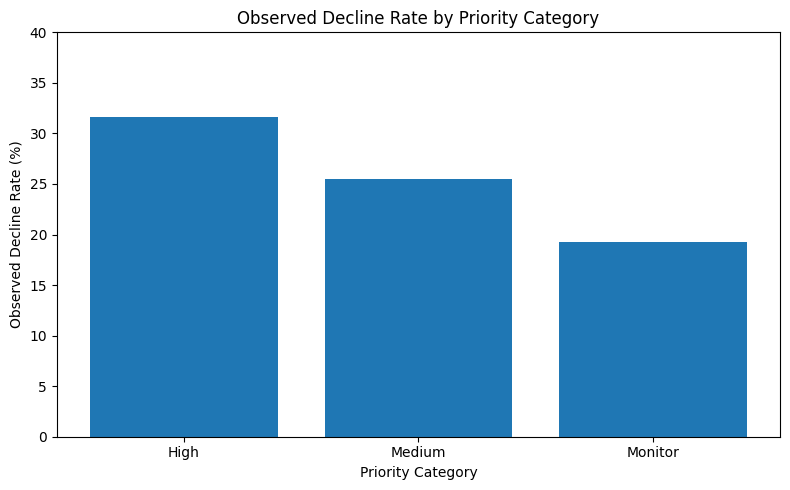

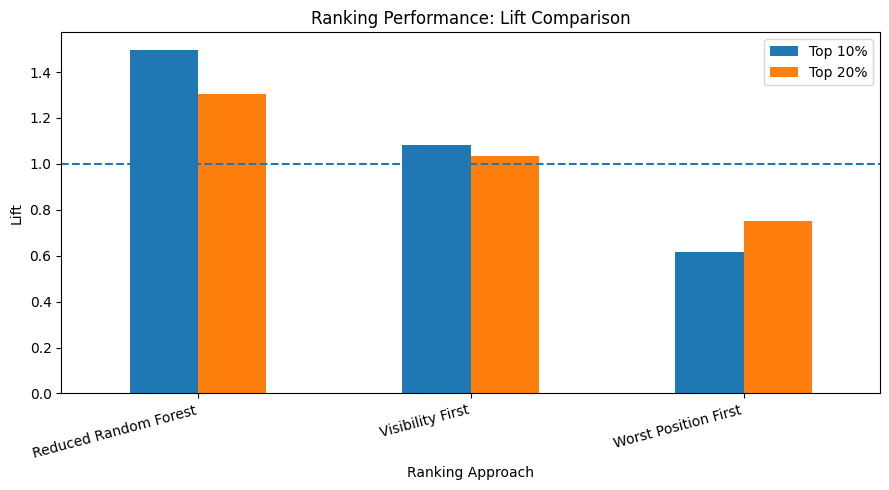

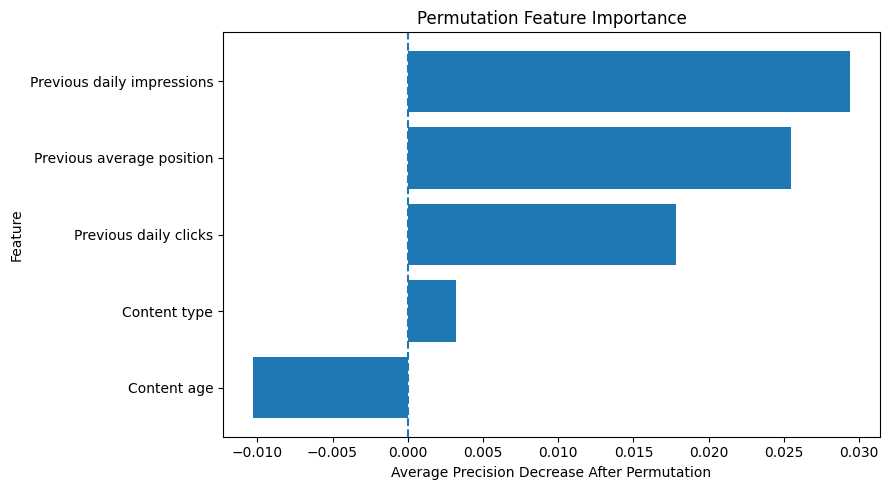


All paper figures and aggregate tables saved.
Output folder: work/outputs/paper_figures

Files:
feature_importance.csv
feature_importance.png
priority_category_performance.png
priority_category_summary.csv
ranking_lift_comparison.csv
ranking_lift_comparison.png


In [48]:

import os
import matplotlib.pyplot as plt
import pandas as pd

# Create a folder for the paper figures
figure_dir = "work/outputs/paper_figures"
os.makedirs(figure_dir, exist_ok=True)


# --------------------------------------------------
# FIGURE 1: Observed decline rate by priority category
# --------------------------------------------------

category_order = ["High", "Medium", "Monitor"]

category_results = (
    ranked_recommendations
    .groupby("priority_category")
    .agg(
        records=("priority_rank", "count"),
        decline_rate=("is_declining", "mean")
    )
    .reindex(category_order)
)

plt.figure(figsize=(8, 5))

plt.bar(
    category_results.index,
    category_results["decline_rate"] * 100
)

plt.title("Observed Decline Rate by Priority Category")
plt.xlabel("Priority Category")
plt.ylabel("Observed Decline Rate (%)")
plt.ylim(0, 40)
plt.tight_layout()

plt.savefig(
    f"{figure_dir}/priority_category_performance.png",
    dpi=300
)
plt.show()


# --------------------------------------------------
# FIGURE 2: Ranking performance comparison
# --------------------------------------------------

ranking_comparison = pd.DataFrame({
    "Approach": [
        "Reduced Random Forest",
        "Visibility First",
        "Worst Position First"
    ],
    "Top 10%": [1.498, 1.084, 0.614],
    "Top 20%": [1.305, 1.035, 0.750]
})

ranking_comparison = ranking_comparison.set_index("Approach")

ranking_comparison.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Ranking Performance: Lift Comparison")
plt.xlabel("Ranking Approach")
plt.ylabel("Lift")
plt.xticks(rotation=15, ha="right")
plt.axhline(y=1.0, linestyle="--")
plt.tight_layout()

plt.savefig(
    f"{figure_dir}/ranking_lift_comparison.png",
    dpi=300
)
plt.show()


# --------------------------------------------------
# FIGURE 3: Permutation feature importance
# --------------------------------------------------

feature_importance = pd.DataFrame({
    "Feature": [
        "Previous daily impressions",
        "Previous average position",
        "Previous daily clicks",
        "Content type",
        "Content age"
    ],
    "Importance": [
        0.0294,
        0.0255,
        0.0178,
        0.0032,
        -0.0103
    ]
})

feature_importance = feature_importance.sort_values(
    "Importance"
)

plt.figure(figsize=(9, 5))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.title("Permutation Feature Importance")
plt.xlabel("Average Precision Decrease After Permutation")
plt.ylabel("Feature")
plt.axvline(x=0, linestyle="--")
plt.tight_layout()

plt.savefig(
    f"{figure_dir}/feature_importance.png",
    dpi=300
)
plt.show()


# --------------------------------------------------
# SAVE AGGREGATE TABLES
# --------------------------------------------------

category_results.to_csv(
    f"{figure_dir}/priority_category_summary.csv"
)

ranking_comparison.to_csv(
    f"{figure_dir}/ranking_lift_comparison.csv"
)

feature_importance.to_csv(
    f"{figure_dir}/feature_importance.csv",
    index=False
)

print("\nAll paper figures and aggregate tables saved.")
print("Output folder:", figure_dir)

print("\nFiles:")
for filename in sorted(os.listdir(figure_dir)):
    print(filename)


## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.
- [ ] My deployed paper has **all 9 sections** — including the **Abstract** at the top and **Acknowledgments & data credit** (the https://flyrank.ai link) at the bottom.
- [ ] **ML-12 done in this notebook's closing cells:** 5-minute demo outline + a social-post cut + a 3-sentence employer-facing summary.
